# Experimento espectral: arquitecturas recurrentes sobre el espectro MaNGA FoV

**Hipótesis a poner a prueba:** una CNN 1D con pooling global no integra el espectro completo (continuo, quiebre de 4000 Å, líneas de absorción), y una arquitectura recurrente que recorra todo el espectro podría extraer más información para separar `temprana = 0.0` de `tardia = 1.0`.

Se usa el mismo manifest, split persistente (`splits_seed42_obj-label_FoV.csv`), caché (`spectra_cache_FoV`, espectro MaNGA observado `FLUX_FoV`, 3600–9000 Å, 4096 muestras, un canal) y protocolo de selección que `experimento_espectros_fov.ipynb` (CNN1D, referencia: ROC-AUC test 0.857). Solo cambia la arquitectura del encoder.

| Variante | Qué prueba |
|---|---|
| `patch_bigru` | RNN "pura": el espectro se divide en 128 patches de 32 muestras y una BiGRU los recorre. |
| `cnn_bigru` | CNN local (256 tokens) + BiGRU que integra el contexto global. |
| `cnn_attn_control` | Control: CNN más profunda con pooling por atención y sin recurrencia. Separa el efecto de la recurrencia del de simplemente tener más capacidad. |

**Cómo leer el resultado:** si ninguna variante supera claramente la referencia (con intervalos de confianza que se traslapen), el límite está en la información del espectro integrado y no en la arquitectura.

In [1]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Callable, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from torch import nn


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

Proyecto: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Dispositivo: cuda


## Configuración e invariantes

- Split, cohorte y caché idénticos a la CNN1D de referencia; no se regeneran.
- Selección de checkpoint, early stopping y elección de época solo con validación; `test` se evalúa una vez por variante, con el mejor checkpoint.
- Una salida logit por galaxia y `BCEWithLogitsLoss`.
- Las RNN son sensibles a gradientes grandes: se usa *gradient clipping* (norma 1.0) en todas las variantes para que la comparación sea equitativa. El learning rate (3e-4) es mayor que el de la referencia (1e-4), cuya curva seguía subajustada.

In [2]:
CONFIG: dict[str, Any] = {
    "experiment_group": "espectros_fov_rnn",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label_FoV.csv",
        "modalities": ["spectrum"],
        "spectrum": {"cache_dir": "data/processed/spectra/spectra_cache_FoV"},
    },
    "model": {
        "embedding_dim": 128,
        "classifier_hidden_dim": 128,
        "dropout": 0.3,
        "patch_size": 32,
        "gru_hidden": 64,
        "gru_layers": 2,
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 60,
        "learning_rate": 3e-4,
        "weight_decay": 1e-4,
        "early_stopping_patience": 10,
        "grad_clip_norm": 1.0,
    },
    "selection_metric": "roc_auc",
}
VARIANTS = ["patch_bigru", "cnn_bigru", "cnn_attn_control"]
BASELINE_DIR = ROOT / "models" / "experiments" / "espectros_fov_cnn1d"


def run_dir(variant: str) -> Path:
    return ROOT / "models" / "experiments" / f"espectros_fov_{variant}"


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
loaders = {"train": train_loader, "validation": validation_loader, "test": test_loader}

for split_name, loader in loaders.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    print(f"{key:16s} {tuple(value.shape) if isinstance(value, torch.Tensor) else type(value).__name__}")
print(f"Fracción de posiciones válidas en el batch: {sample_batch['spectrum_mask'].float().mean():.3f}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,)
spectrum         (32, 1, 4096)
spectrum_mask    (32, 4096)
Fracción de posiciones válidas en el batch: 1.000


## Modelos

Los tres encoders reciben `spectrum [B, 1, 4096]` y `spectrum_mask [B, 4096]` y devuelven un embedding `[B, 128]`.

**Manejo de la máscara.** Las posiciones sin cobertura se anulan antes de entrar a la red, la máscara se propaga a nivel de patch/token (un token es válido si contiene al menos una muestra válida, igual que el `max_pool1d` de la CNN de referencia) y todo pooling es enmascarado. Así el relleno con ceros no contribuye al embedding.

**Pooling media + máximo.** Las RNN no pierden la posición, pero la media enmascarada sola diluye líneas aisladas; se concatenan la media y el máximo de los estados ocultos y se proyectan al embedding.

In [3]:
def masked_mean_max(x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    """x: [B, T, D], mask: [B, T] bool -> [B, 2D]."""
    weights = mask.unsqueeze(-1).to(x.dtype)
    mean = (x * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1.0)
    maximum = x.masked_fill(~mask.unsqueeze(-1), float("-inf")).amax(dim=1)
    return torch.cat([mean, torch.nan_to_num(maximum, neginf=0.0)], dim=-1)


def check_inputs(spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    if spectrum.ndim != 3 or mask.shape != spectrum.shape[:1] + spectrum.shape[2:]:
        raise ValueError("Se esperaba spectrum=[B, C, L] y spectrum_mask=[B, L].")
    return spectrum * mask.bool().unsqueeze(1)


def projection_head(in_dim: int, cfg: Mapping[str, Any]) -> nn.Sequential:
    return nn.Sequential(nn.Linear(in_dim, int(cfg["embedding_dim"])), nn.ReLU(inplace=True), nn.Dropout(float(cfg["dropout"])))


class PatchBiGRUEncoder(nn.Module):
    def __init__(self, in_channels: int, seq_len: int, cfg: Mapping[str, Any]) -> None:
        super().__init__()
        self.patch = int(cfg["patch_size"])
        if seq_len % self.patch:
            raise ValueError("La longitud espectral debe ser múltiplo de patch_size.")
        hidden = int(cfg["gru_hidden"])
        self.embed = nn.Sequential(nn.Linear(in_channels * self.patch, hidden * 2), nn.LayerNorm(hidden * 2), nn.GELU())
        self.gru = nn.GRU(
            hidden * 2, hidden, num_layers=int(cfg["gru_layers"]), batch_first=True,
            bidirectional=True, dropout=float(cfg["dropout"]),
        )
        self.projection = projection_head(4 * hidden, cfg)

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        spectrum = check_inputs(spectrum, mask)
        b, c, length = spectrum.shape
        n_patches = length // self.patch
        tokens = spectrum.view(b, c, n_patches, self.patch).permute(0, 2, 1, 3).reshape(b, n_patches, c * self.patch)
        token_mask = mask.bool().view(b, n_patches, self.patch).any(dim=-1)
        states, _ = self.gru(self.embed(tokens) * token_mask.unsqueeze(-1))
        return self.projection(masked_mean_max(states, token_mask))


class ConvTokenizer(nn.Module):
    """Convoluciones con stride 2; propaga la máscara y anula el relleno en cada etapa."""

    def __init__(self, channels: tuple[int, ...], kernel: int) -> None:
        super().__init__()
        self.kernel = kernel
        self.blocks = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv1d(a, b, kernel_size=kernel, stride=2, padding=kernel // 2),
                    nn.BatchNorm1d(b),
                    nn.GELU(),
                )
                for a, b in zip(channels[:-1], channels[1:])
            ]
        )

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        mask = mask.bool()
        for block in self.blocks:
            spectrum = block(spectrum)
            mask = F.max_pool1d(mask.float().unsqueeze(1), self.kernel, stride=2, padding=self.kernel // 2).squeeze(1).bool()
            spectrum = spectrum * mask.unsqueeze(1)
        return spectrum.transpose(1, 2), mask  # [B, T, D], [B, T]


class CNNBiGRUEncoder(nn.Module):
    def __init__(self, in_channels: int, cfg: Mapping[str, Any]) -> None:
        super().__init__()
        hidden = int(cfg["gru_hidden"])
        self.tokenizer = ConvTokenizer((in_channels, 32, 64, 64, 128), kernel=7)  # 4096 -> 256 tokens
        self.gru = nn.GRU(
            128, hidden, num_layers=int(cfg["gru_layers"]), batch_first=True,
            bidirectional=True, dropout=float(cfg["dropout"]),
        )
        self.projection = projection_head(4 * hidden, cfg)

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        tokens, token_mask = self.tokenizer(check_inputs(spectrum, mask), mask)
        states, _ = self.gru(tokens * token_mask.unsqueeze(-1))
        return self.projection(masked_mean_max(states, token_mask))


class CNNAttentionEncoder(nn.Module):
    """Control sin recurrencia: CNN más profunda/ancha y pooling por atención enmascarada."""

    def __init__(self, in_channels: int, cfg: Mapping[str, Any]) -> None:
        super().__init__()
        self.tokenizer = ConvTokenizer((in_channels, 32, 64, 128, 128, 256), kernel=7)  # 4096 -> 128 tokens
        self.score = nn.Linear(256, 1)
        self.projection = projection_head(256, cfg)

    def forward(self, spectrum: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        tokens, token_mask = self.tokenizer(check_inputs(spectrum, mask), mask)
        scores = self.score(tokens).squeeze(-1).masked_fill(~token_mask, float("-inf"))
        weights = torch.softmax(scores, dim=1).nan_to_num(0.0)
        return self.projection((weights.unsqueeze(-1) * tokens).sum(dim=1))


class SpectrumClassifier(nn.Module):
    def __init__(self, encoder: nn.Module, cfg: Mapping[str, Any]) -> None:
        super().__init__()
        self.spectrum_encoder = encoder
        self.classifier = nn.Sequential(
            nn.Linear(int(cfg["embedding_dim"]), int(cfg["classifier_hidden_dim"])),
            nn.ReLU(inplace=True),
            nn.Dropout(float(cfg["dropout"])),
            nn.Linear(int(cfg["classifier_hidden_dim"]), 1),
        )

    def forward(self, batch: Mapping[str, Any]) -> torch.Tensor:
        return self.classifier(self.spectrum_encoder(batch["spectrum"], batch["spectrum_mask"])).squeeze(1)


def build_model(variant: str, config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    cfg = config["model"]
    channels, length = batch["spectrum"].shape[1], batch["spectrum"].shape[2]
    encoders: dict[str, Callable[[], nn.Module]] = {
        "patch_bigru": lambda: PatchBiGRUEncoder(channels, length, cfg),
        "cnn_bigru": lambda: CNNBiGRUEncoder(channels, cfg),
        "cnn_attn_control": lambda: CNNAttentionEncoder(channels, cfg),
    }
    return SpectrumClassifier(encoders[variant](), cfg)


def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {k: v.to(device, non_blocking=True) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}


# Prueba de forward y de que el relleno fuera de cobertura no afecta la salida
for variant in VARIANTS:
    model = build_model(variant, CONFIG, sample_batch).to(DEVICE).eval()
    batch_dev = move_batch_to_device(sample_batch, DEVICE)
    with torch.no_grad():
        logits = model(batch_dev)
        altered = dict(batch_dev)
        altered["spectrum"] = batch_dev["spectrum"] + 100.0 * (~batch_dev["spectrum_mask"]).unsqueeze(1)
        logits_altered = model(altered)
    assert logits.shape == sample_batch["label"].shape and torch.isfinite(logits).all()
    assert torch.allclose(logits, logits_altered, atol=1e-5), "El relleno fuera de cobertura afecta la salida."
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{variant:18s} parámetros={n_params:>9,d}  logits={tuple(logits.shape)}  invariante a relleno: OK")

patch_bigru        parámetros=  203,009  logits=(32,)  invariante a relleno: OK
cnn_bigru          parámetros=  299,969  logits=(32,)  invariante a relleno: OK
cnn_attn_control   parámetros=  467,586  logits=(32,)  invariante a relleno: OK


## Entrenamiento

Mismo loop que la referencia (`AdamW`, `BCEWithLogitsLoss`, early stopping por ROC-AUC de validación) con la adición de *gradient clipping*. Para cada variante se reinicia la semilla, de modo que la inicialización y el orden de los batches no dependen del orden de ejecución.

In [4]:
def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    if logits.shape != batch["label"].shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(batch['label'].shape)}.")
    return logits


def train_epoch(model, loader, optimizer, criterion, device, clip_norm) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        total_loss += criterion(logits, batch["label"]).item() * batch["label"].numel()
        probabilities = torch.sigmoid(logits)
        all_true.append(batch["label"].cpu().numpy())
        all_pred.append((probabilities >= 0.5).to(torch.int64).cpu().numpy())
        all_proba.append(probabilities.cpu().numpy())
    return total_loss / len(loader.dataset), np.concatenate(all_true), np.concatenate(all_pred), np.concatenate(all_proba)


def fit(model, train_loader, validation_loader, config, device, checkpoint_path: Path) -> pd.DataFrame:
    tc = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=tc["learning_rate"], weight_decay=tc["weight_decay"])
    history: list[dict[str, float]] = []
    best_score, best_state, stale = float("-inf"), None, 0

    for epoch in range(1, tc["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device, tc["grad_clip_norm"])
        val_loss, y_true, y_pred, y_proba = evaluate_epoch(model, validation_loader, criterion, device)
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": val_loss,
            "validation_accuracy": float(metrics["accuracy"]),
            "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "validation_f1": f1_score(y_true, y_pred, zero_division=0),
            "validation_roc_auc": float(metrics["roc_auc"]),
            "seconds": time.perf_counter() - started_at,
        })
        print(f"[{epoch:02d}/{tc['epochs']}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} val_auc={metrics['roc_auc']:.4f}")
        if score > best_score:
            best_score, best_state, stale = score, copy.deepcopy(model.state_dict()), 0
        else:
            stale += 1
            if stale >= tc["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state}, checkpoint_path)
    return pd.DataFrame(history)


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(v) for v in value]
    return value


@torch.no_grad()
def predict_split(model, dataset, split_name: str) -> pd.DataFrame:
    loader = torch.utils.data.DataLoader(
        dataset, batch_size=CONFIG["training"]["batch_size"], shuffle=False,
        num_workers=CONFIG["training"]["num_workers"], pin_memory=CONFIG["training"]["pin_memory"],
    )
    model.eval()
    frames = []
    for batch in loader:
        labels = batch["label"].to(torch.int64).numpy()
        probas = torch.sigmoid(model(move_batch_to_device(batch, DEVICE))).cpu().numpy().astype(np.float64)
        frames.append(pd.DataFrame({
            "name": list(batch["id"]), "split": split_name, "y_true": labels,
            "y_proba": probas, "y_pred": (probas >= 0.5).astype(np.int64),
        }))
    return pd.concat(frames, ignore_index=True)


def run_variant(variant: str) -> dict[str, Any]:
    out = run_dir(variant)
    out.mkdir(parents=True, exist_ok=True)
    config = {**CONFIG, "experiment_name": f"espectros_fov_{variant}", "variant": variant}

    set_seed(CONFIG["seed"])
    tr, va, te = build_dataloaders(config)
    batch = next(iter(tr))
    model = build_model(variant, config, batch).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n===== {variant} ({n_params:,d} parámetros) =====")

    started = time.perf_counter()
    history = fit(model, tr, va, config, DEVICE, out / "best_model.pt")
    train_seconds = time.perf_counter() - started

    test_loss, y_true, y_pred, y_proba = evaluate_epoch(model, te, nn.BCEWithLogitsLoss(), DEVICE)
    metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
    print(f"{variant}: test_loss={test_loss:.4f} acc={metrics['accuracy']:.4f} auc={metrics['roc_auc']:.4f}")

    predictions = pd.concat(
        [predict_split(model, loader.dataset, name) for name, loader in {"train": tr, "validation": va, "test": te}.items()],
        ignore_index=True,
    )
    int_to_label = {0: "temprana", 1: "tardia"}
    predictions["label"] = predictions["y_true"].map(int_to_label)
    predictions["pred_label"] = predictions["y_pred"].map(int_to_label)
    predictions["correct"] = predictions["y_true"] == predictions["y_pred"]
    predictions = predictions[["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]]

    results = {"test_loss": test_loss, **metrics}
    (out / "config.json").write_text(json.dumps(to_jsonable(config), indent=2), encoding="utf-8")
    (out / "results.json").write_text(json.dumps(to_jsonable(results), indent=2), encoding="utf-8")
    (out / "test_metrics.json").write_text(json.dumps(to_jsonable(results), indent=2), encoding="utf-8")
    history.to_csv(out / "history.csv", index=False)
    predictions.to_csv(out / "predictions.csv", index=False)
    return {
        "variant": variant, "parameters": n_params, "best_epoch": int(history["validation_roc_auc"].idxmax()) + 1,
        "epochs_run": len(history), "train_seconds": train_seconds, "history": history,
        "y_true": y_true, "y_proba": y_proba, "metrics": metrics, "test_loss": test_loss,
    }

### Variante 1: BiGRU sobre patches

In [5]:
RUNS: dict[str, dict[str, Any]] = {}
RUNS["patch_bigru"] = run_variant("patch_bigru")


===== patch_bigru (203,009 parámetros) =====
[01/60] train_loss=0.6262 val_loss=0.5094 val_auc=0.8475
[02/60] train_loss=0.4560 val_loss=0.4225 val_auc=0.8845
[03/60] train_loss=0.4244 val_loss=0.4106 val_auc=0.8894
[04/60] train_loss=0.4143 val_loss=0.4118 val_auc=0.8927
[05/60] train_loss=0.4014 val_loss=0.3994 val_auc=0.8955
[06/60] train_loss=0.3979 val_loss=0.3835 val_auc=0.9007
[07/60] train_loss=0.3857 val_loss=0.4172 val_auc=0.9012
[08/60] train_loss=0.3811 val_loss=0.4020 val_auc=0.9080
[09/60] train_loss=0.3716 val_loss=0.3858 val_auc=0.9037
[10/60] train_loss=0.3737 val_loss=0.3920 val_auc=0.9065
[11/60] train_loss=0.3624 val_loss=0.3837 val_auc=0.9080
[12/60] train_loss=0.3574 val_loss=0.4024 val_auc=0.9041
[13/60] train_loss=0.3590 val_loss=0.3846 val_auc=0.9106
[14/60] train_loss=0.3515 val_loss=0.3657 val_auc=0.9120
[15/60] train_loss=0.3459 val_loss=0.4076 val_auc=0.9093
[16/60] train_loss=0.3498 val_loss=0.4167 val_auc=0.9136
[17/60] train_loss=0.3463 val_loss=0.3742 

### Variante 2: CNN + BiGRU

In [6]:
RUNS["cnn_bigru"] = run_variant("cnn_bigru")


===== cnn_bigru (299,969 parámetros) =====
[01/60] train_loss=0.4600 val_loss=0.4051 val_auc=0.8882
[02/60] train_loss=0.4013 val_loss=0.4045 val_auc=0.8966
[03/60] train_loss=0.3891 val_loss=0.3847 val_auc=0.9036
[04/60] train_loss=0.3760 val_loss=0.4037 val_auc=0.9025
[05/60] train_loss=0.3718 val_loss=0.3807 val_auc=0.9045
[06/60] train_loss=0.3604 val_loss=0.3960 val_auc=0.9046
[07/60] train_loss=0.3537 val_loss=0.3796 val_auc=0.9039
[08/60] train_loss=0.3486 val_loss=0.3844 val_auc=0.9015
[09/60] train_loss=0.3370 val_loss=0.4212 val_auc=0.8995
[10/60] train_loss=0.3231 val_loss=0.3942 val_auc=0.9014
[11/60] train_loss=0.3105 val_loss=0.4262 val_auc=0.8984
[12/60] train_loss=0.2937 val_loss=0.4185 val_auc=0.8967
[13/60] train_loss=0.2810 val_loss=0.4317 val_auc=0.8842
[14/60] train_loss=0.2651 val_loss=0.4660 val_auc=0.8983
[15/60] train_loss=0.2507 val_loss=0.4928 val_auc=0.8912
[16/60] train_loss=0.2320 val_loss=0.5085 val_auc=0.8874
Early stopping por validación.
cnn_bigru: te

### Variante 3: control CNN con atención (sin recurrencia)

In [7]:
RUNS["cnn_attn_control"] = run_variant("cnn_attn_control")


===== cnn_attn_control (467,586 parámetros) =====
[01/60] train_loss=0.4691 val_loss=0.4133 val_auc=0.8859
[02/60] train_loss=0.4180 val_loss=0.4046 val_auc=0.8891
[03/60] train_loss=0.4042 val_loss=0.4346 val_auc=0.8877
[04/60] train_loss=0.3897 val_loss=0.3899 val_auc=0.8978
[05/60] train_loss=0.3822 val_loss=0.4112 val_auc=0.8894
[06/60] train_loss=0.3747 val_loss=0.4594 val_auc=0.8933
[07/60] train_loss=0.3626 val_loss=0.4013 val_auc=0.8947
[08/60] train_loss=0.3594 val_loss=0.3796 val_auc=0.9036
[09/60] train_loss=0.3446 val_loss=0.4065 val_auc=0.8995
[10/60] train_loss=0.3358 val_loss=0.4028 val_auc=0.8979
[11/60] train_loss=0.3274 val_loss=0.4178 val_auc=0.8927
[12/60] train_loss=0.3204 val_loss=0.4180 val_auc=0.8872
[13/60] train_loss=0.3129 val_loss=0.4664 val_auc=0.8926
[14/60] train_loss=0.2875 val_loss=0.4553 val_auc=0.8882
[15/60] train_loss=0.2739 val_loss=0.5070 val_auc=0.8792
[16/60] train_loss=0.2629 val_loss=0.5507 val_auc=0.8751
[17/60] train_loss=0.2537 val_loss=0.

## Curvas de entrenamiento

Señales a vigilar: si `train_loss` sigue bajando mientras `validation_loss` sube hay sobreajuste; si ambas se estancan en valores altos, el modelo está limitado en capacidad o en información.

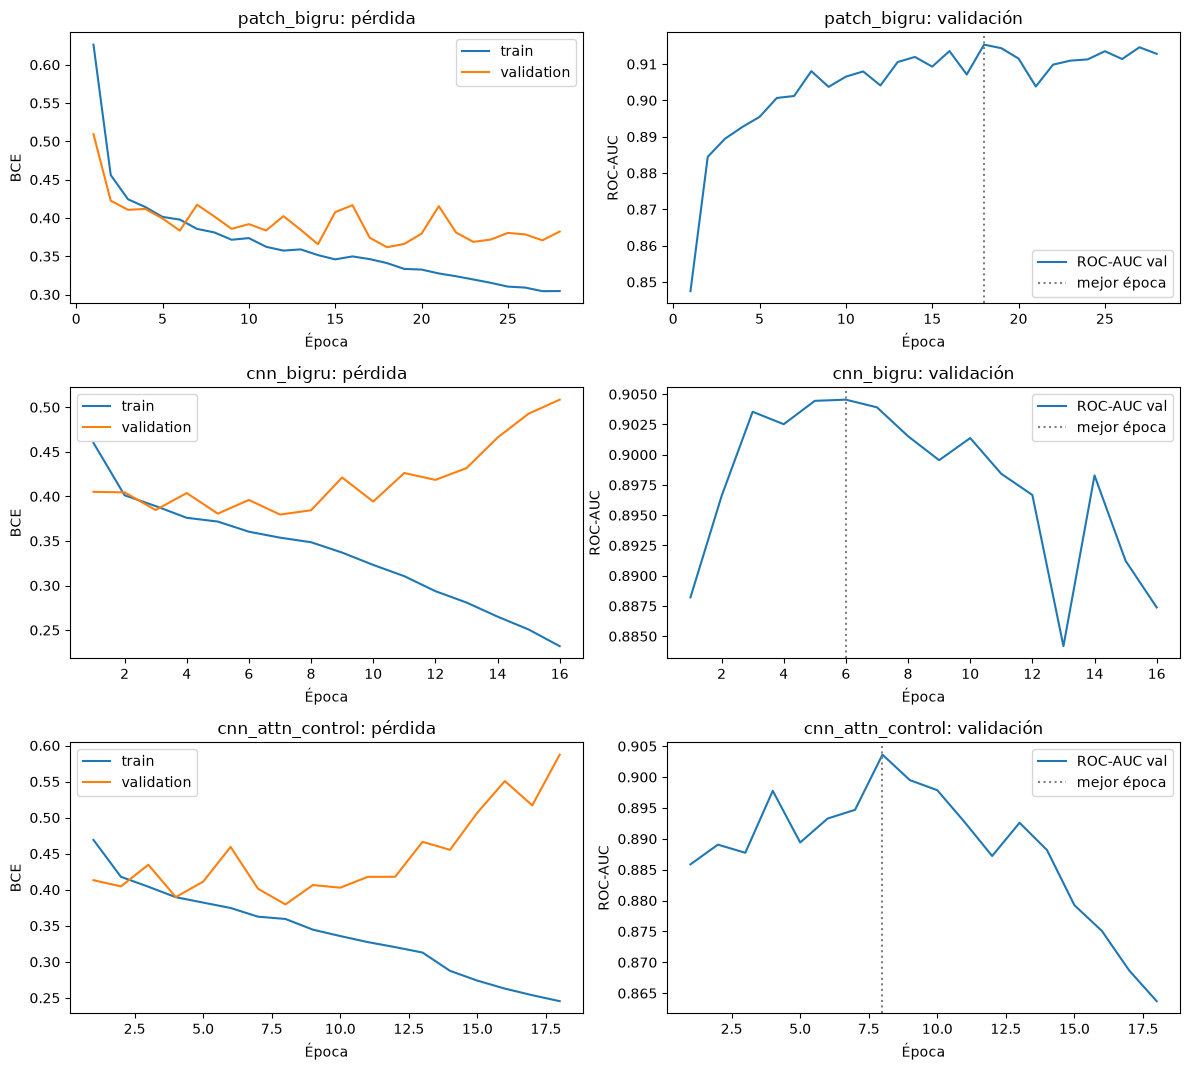

In [8]:
figure, axes = plt.subplots(len(RUNS), 2, figsize=(12, 3.6 * len(RUNS)), squeeze=False)
for row, (variant, run) in enumerate(RUNS.items()):
    h = run["history"]
    axes[row, 0].plot(h["epoch"], h["train_loss"], label="train")
    axes[row, 0].plot(h["epoch"], h["validation_loss"], label="validation")
    axes[row, 0].set(title=f"{variant}: pérdida", xlabel="Época", ylabel="BCE")
    axes[row, 0].legend()
    axes[row, 1].plot(h["epoch"], h["validation_roc_auc"], label="ROC-AUC val")
    axes[row, 1].axvline(run["best_epoch"], color="gray", ls=":", label="mejor época")
    axes[row, 1].set(title=f"{variant}: validación", xlabel="Época", ylabel="ROC-AUC")
    axes[row, 1].legend()
figure.tight_layout()

## Comparación en test contra la CNN1D de referencia

Los intervalos de confianza del ROC-AUC se calculan por *bootstrap* de las galaxias de test (1000 remuestreos). Con ~1400 galaxias, diferencias de ~0.01 de AUC suelen caer dentro del ruido: un intervalo traslapado con el de la referencia no es evidencia de mejora. La referencia es una sola corrida con otra configuración de optimización (lr 1e-4), por lo que conviene leer la comparación como orientativa.

In [9]:
def bootstrap_auc(y_true: np.ndarray, y_proba: np.ndarray, n: int = 1000, seed: int = 0) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) == 2:
            aucs.append(roc_auc_score(y_true[idx], y_proba[idx]))
    low, high = np.percentile(aucs, [2.5, 97.5])
    return float(low), float(high)


baseline_predictions = pd.read_csv(BASELINE_DIR / "predictions.csv")
baseline_test = baseline_predictions[baseline_predictions["split"] == "test"]
baseline_metrics = json.loads((BASELINE_DIR / "results.json").read_text())

rows = [{
    "modelo": "cnn1d (referencia)", "parámetros": np.nan, "mejor época": np.nan,
    "accuracy": baseline_metrics["accuracy"], "f1 tardía": baseline_metrics["report"]["1.0"]["f1-score"],
    "roc_auc": baseline_metrics["roc_auc"],
    "IC95 auc": bootstrap_auc(baseline_test["y_true"].to_numpy(), baseline_test["y_proba"].to_numpy()),
    "test_loss": baseline_metrics["test_loss"], "segundos": np.nan,
}]
for variant, run in RUNS.items():
    m = run["metrics"]
    rows.append({
        "modelo": variant, "parámetros": run["parameters"], "mejor época": run["best_epoch"],
        "accuracy": m["accuracy"], "f1 tardía": m["report"]["1.0"]["f1-score"], "roc_auc": m["roc_auc"],
        "IC95 auc": bootstrap_auc(run["y_true"], run["y_proba"]), "test_loss": run["test_loss"],
        "segundos": run["train_seconds"],
    })
comparison = pd.DataFrame(rows)
comparison["IC95 auc"] = comparison["IC95 auc"].map(lambda ci: f"[{ci[0]:.3f}, {ci[1]:.3f}]")
comparison.to_csv(ROOT / "models" / "experiments" / "espectros_fov_rnn_comparison.csv", index=False)
comparison.round(4)

,modelo,parámetros,mejor época,accuracy,f1 tardía,roc_auc,IC95 auc,test_loss,segundos
0,cnn1d (referencia),NaN,NaN,0.7947,0.8398,0.8572,"[0.837, 0.877]",0.4566,NaN
1,patch_bigru,203009.0,18.0,0.8525,0.8792,0.9170,"[0.901, 0.931]",0.3593,101.4674
2,cnn_bigru,299969.0,6.0,0.8468,0.8751,0.9122,"[0.896, 0.926]",0.3719,60.5494
3,cnn_attn_control,467586.0,8.0,0.8418,0.8706,0.9011,"[0.884, 0.917]",0.3849,66.1683


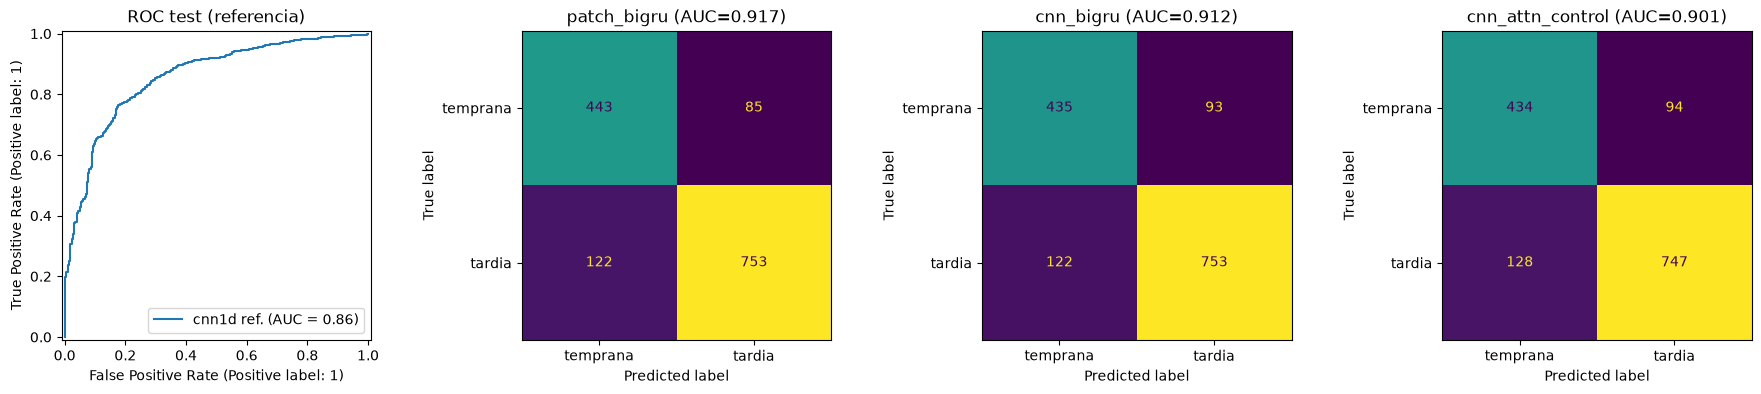

In [10]:
figure, axes = plt.subplots(1, len(RUNS) + 1, figsize=(4.5 * (len(RUNS) + 1), 4))
RocCurveDisplay.from_predictions(
    baseline_test["y_true"], baseline_test["y_proba"], ax=axes[0], name="cnn1d ref."
)
axes[0].set_title("ROC test (referencia)")
for ax, (variant, run) in zip(axes[1:], RUNS.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=run["metrics"]["confusion_matrix"], display_labels=["temprana", "tardia"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(f"{variant} (AUC={run['metrics']['roc_auc']:.3f})")
figure.tight_layout()

## Interpretación

Completar tras ejecutar, con los números de la tabla:

1. ¿Alguna variante recurrente supera a la CNN1D de referencia fuera del IC95 del AUC?
2. ¿`cnn_bigru` supera a `cnn_attn_control`? Si no, la recurrencia no aporta frente a simplemente más capacidad.
3. ¿`patch_bigru` (RNN pura) queda por debajo de las híbridas? Sería coherente con que la CNN local es útil para capturar líneas.
4. Si todas quedan alrededor de 0.86–0.89 (el MLP de poblaciones STARLIGHT llega a 0.895 y la CNN-atención sobre STARLIGHT a 0.907), el techo parece ser la información del espectro integrado FoV y no la arquitectura.

Limitaciones: una sola semilla por variante, un solo split y el espectro es el observado MaNGA FoV (ruido incluido), a diferencia del modelo ajustado de STARLIGHT; compararlos sirve para ver cuánto aporta el ajuste de poblaciones. Ver guía 22.1.